In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob

In [2]:
graph_type = 'ER'
coup_type = 'ising'
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(np.float64(0.25541281188299536), np.float64(0.5493061443340548))

In [3]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/tmp/coal_time_DS_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
df

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.20,F_beta_Glauber,False,100,10,10000000,100,10,1778.0,785.168644
1,0.20,F_beta_Glauber,False,100,10,10000000,500,10,13434.0,6005.889043
2,0.20,F_beta_Glauber,False,100,10,10000000,1000,10,30889.9,7352.227995
3,0.20,F_beta_Glauber,False,100,10,10000000,2500,10,87332.4,14363.500021
4,0.20,F_beta_Glauber,False,100,10,10000000,5000,10,233810.8,50393.357050
5,0.21,F_beta_Glauber,False,100,10,10000000,100,10,1640.6,218.170667
6,0.21,F_beta_Glauber,False,100,10,10000000,500,10,15726.3,6498.638089
7,0.21,F_beta_Glauber,False,100,10,10000000,1000,10,33549.3,7950.523958
8,0.21,F_beta_Glauber,False,100,10,10000000,2500,10,121789.6,21941.614490
9,0.21,F_beta_Glauber,False,100,10,10000000,5000,10,283569.7,107933.238054


# Scaling of coalescence times

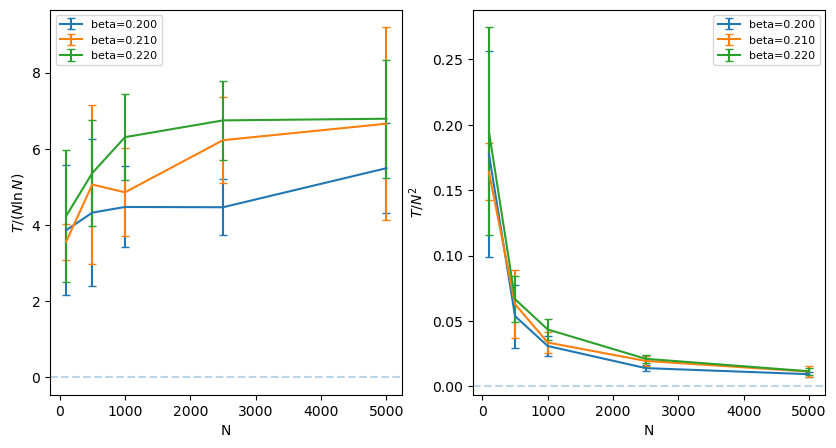

In [6]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['n_coal'] == df['n_runs']) 
)
df_filtered = df[mask]

#fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
scalings = {
#    r'$T / N$': (lambda N, T: T / N, 
#                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        if beta > beta_uni:
            continue
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    #ax.set_xscale('log')   
    ax.legend(fontsize=8)
plt.show()

# Proba of coalescence

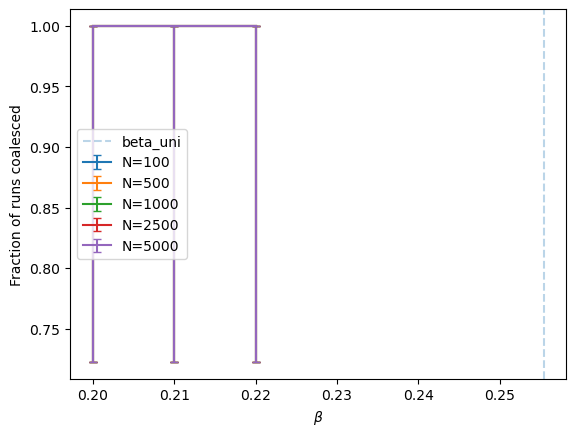

In [6]:

mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) 
)
df_filtered = df[mask]

N_to_exclude = []
for N in df_filtered['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.axvline(beta_uni, linestyle='--', alpha=0.3, label='beta_uni')
plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()